# Hydrofoil shape optimization with reinforcement learning

The usual way to optimize an airfoil shape is with a genetic algorithm: generate thousands of random shapes, score them all, keep the best ones. That works, but it wastes a huge number of solver calls.

Here we try something different. We treat shape design as a step by step game:

- The agent starts with some random hydrofoil section.
- It can make 40 small moves. Each move changes one CST (Kulfan) weight a little bit.
- After every move, NeuralFoil (a fast neural network version of XFOIL) gives us the new L/D in about a millisecond.
- A PPO agent from Stable-Baselines3 learns which moves actually help.

| MDP piece | What it is |
|---|---|
| State (20 numbers) | 8 upper + 8 lower CST weights, current L/D, mid chord thickness, log Re, alpha |
| Action (32 choices) | pick one of the 16 weights, move it up or down by delta = 0.01 |
| Reward | change in L/D after the move. Moves that break the shape rules get rejected (undone, small penalty) |
| Episode | 40 moves, then it starts over on a new random task |

Every episode gets a random starting shape, a random Reynolds number between 1e5 and 1e7 and a random angle of attack between 0 and 7 degrees. Re and alpha are also inputs to the network. So the agent cannot just memorize one good sequence of moves, it has to learn how shape changes affect performance at different flow conditions.

The starting shapes are not all NACA sections either. `reset()` picks from a mix of real airfoil families (Selig, Eppler, NASA GA, Clark, MH, NACA) that we fit into our CST basis, so the agent sees many different kinds of sections during training.

In [1]:
# run this once if the packages are missing:
# !pip install -q neuralfoil stable-baselines3

import math, time
import numpy as np
import matplotlib.pyplot as plt
import neuralfoil as nf
import aerosandbox as asb
import gymnasium as gym
from gymnasium import spaces
from gymnasium.wrappers import TimeLimit
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import EvalCallback

TIMESTEPS  = 350_000    # takes around 9 minutes on a laptop CPU. 100k already works okay
MODEL_SIZE = "xxsmall"  # NeuralFoil model size, bigger = more accurate but slower
SEED       = 42

## 1. CST geometry and the shape rules

Both surfaces are written in the 8 weight CST family:

$$y_{upper}(x) = C(x)\sum_i w^{u}_i B_i(x), \qquad y_{lower}(x) = -C(x)\sum_i w^{l}_i B_i(x), \qquad C(x) = \sqrt{x}\,(1-x)$$

where $B_i$ are the degree 7 Bernstein polynomials. Three reasons why CST is a good choice here:

1. A shape is just 16 numbers, and NeuralFoil can get those weights directly, so one environment step costs about 1 ms. No meshing, no coordinates to manage.
2. The class function $C(x)$ forces the shape to close at the leading edge and at the trailing edge, exactly like a real section does.
3. If all weights are >= 0 the surface is always smooth and single valued (this is a known CST property from Kulfan's paper). We keep the weights in $[0, w_{box}]$, so the agent literally cannot build a crossed or self intersecting shape.

On top of that we check a few rules that real sections follow, and any move that breaks them just gets rejected:

| Rule | Bound | Reason |
|---|---|---|
| max thickness of the section | <= 18% | real hydrofoil sections are roughly 8 to 18% |
| thickness in the spar region x in [0.2, 0.7] | >= 4% | the structure cannot be a knife edge in the middle |
| local thickness for x in (0, 0.95] | > 0.2% | no razor thin pinch anywhere before the trailing edge |
| camber | <= 6% | real sections rarely go past 4 to 6% |
| surface wiggles | <= 2 direction changes | each surface stays smooth, no bumpy shapes |

Thickness is exactly 0 at x=0 and x=1 by construction , so when we check thickness rules we have to ignore those two points.


In [2]:
N_W = 8                                                        # CST weights per surface
X = (1 - np.cos(np.pi * np.linspace(0, 1, 65))) / 2           # cosine spaced x grid
B = np.array([[math.comb(N_W-1, i) * x**i * (1-x)**(N_W-1-i) for i in range(N_W)] for x in X])
A = (np.sqrt(X) * (1 - X))[:, None] * B                        # design matrix: y_u = A @ w_u
PINV = np.linalg.pinv(A)                                       # for fitting start shapes
MASK = (X >= 0.2) & (X <= 0.7)                                 # spar region
THIN = (X > 0.002) & (X <= 0.95)    # thickness check, excluding LE/TE where it is 0

def geom(wu, wl):
    yu, yl = A @ wu, -(A @ wl)
    return yu, yl, yu - yl                                     # upper, lower, thickness

def coords(yu, yl):
    """Airfoil contour (TE -> LE -> TE), used for the verification calls."""
    return np.vstack([np.column_stack([X[::-1], yu[::-1]]), np.column_stack([X[1:], yl[1:]])])

def solve(wu, wl, alpha, Re, model_size=MODEL_SIZE):
    """L/D from NeuralFoil, straight from the CST weights (about 0.5 ms)."""
    a = nf.get_aero_from_kulfan_parameters(
        {"upper_weights": wu, "lower_weights": -wl, "leading_edge_weight": 0.0, "TE_thickness": 0.0},
        alpha=alpha, Re=Re, model_size=model_size)
    ld = np.nan_to_num(a["CL"].item() / max(a["CD"].item(), 1e-6), nan=-10.0)
    return float(np.clip(ld, -20.0, 250.0))

def _wiggles(y):
    """Direction changes with a meaningful amplitude (smooth sections have <= 2)."""
    d = np.diff(y)
    return int(np.sum((d[:-1] * d[1:] < 0) & (np.abs(d[:-1]) > 1e-4) & (np.abs(d[1:]) > 1e-4)))

def realistic(wu, wl, t_min=0.04, t_max=0.18, camber_max=0.06):
    """The shape rules from the table above. Crossing is already impossible because
    the weights stay >= 0 and the class function closes the section."""
    yu, yl, th = geom(wu, wl)
    return (th[THIN].min() > 0.002
            and th[MASK].min() >= t_min
            and th.max() <= t_max
            and np.abs(yu + yl).max() / 2 <= camber_max
            and _wiggles(yu) <= 2 and _wiggles(yl) <= 2)

# --- starting shapes from real airfoil families ---
# AeroSandbox ships a database of real airfoil coordinates. We pick a spread of
# well known sections from different families and fit each one into our CST basis.
START_FOILS = ["sd7037", "sd7062", "sd7003",      # Selig (sailplane / UAV style)
               "e1098", "e63",                    # Eppler
               "ag25", "ag35",                    # NASA general aviation
               "clarky", "mh32", "s8036",         # classic, glider, wind turbine
               "naca2412", "naca4412", "naca0012"]

def fit_cst(af):
    """Fit a database airfoil into our 8 + 8 CST basis (least squares on the x grid)."""
    af = af.normalize()
    up, lo = af.upper_coordinates(), af.lower_coordinates()
    xu, iu = np.unique(np.round(up[:, 0], 5), return_index=True); yu = up[iu, 1]
    xl, il = np.unique(np.round(lo[:, 0], 5), return_index=True); yl = lo[il, 1]
    wu = np.clip(PINV @ np.interp(X, xu, yu), 0.001, 0.35)
    wl = np.clip(PINV @ (-np.interp(X, xl, yl)), 0.001, 0.35)
    return wu, wl

FOIL_WEIGHTS = {name: fit_cst(asb.Airfoil(name=name)) for name in START_FOILS}
print("pre-fitted", len(FOIL_WEIGHTS), "starting shapes:", ", ".join(START_FOILS))

pre-fitted 13 starting shapes: sd7037, sd7062, sd7003, e1098, e63, ag25, ag35, clarky, mh32, s8036, naca2412, naca4412, naca0012


## 2. The environment

`reset()` builds a random task. Half the time it takes one of the pre-fitted database foils, half the time it generates a random NACA 4 digit style section (random thickness, camber and camber position). Either way it adds a little noise to the weights so no two episodes start from the exact same shape, then it samples Re and alpha. `step()` applies one of the 32 moves. If the move breaks a shape rule it is undone and the agent gets a small penalty, and the episode just keeps going. 

In [3]:
class FoilEnv(gym.Env):
    """One episode = 40 sculpting moves on one random start foil at a random condition."""

    metadata = {"render_modes": []}

    def __init__(self, n_steps=40, delta=0.01, model_size=MODEL_SIZE, w_box=0.35,
                 alpha_range=(0.0, 7.0), re_range=(1e5, 1e7), rej_penalty=-0.3):
        super().__init__()
        self.n_steps, self.delta, self.model_size = n_steps, delta, model_size
        self.w_box, self.rej_penalty = w_box, rej_penalty
        self.alpha_range, self.re_range = alpha_range, re_range
        self.action_space = spaces.Discrete(4 * N_W)            # 16 weights x {up, down}
        self.observation_space = spaces.Box(-5.0, 5.0, (2*N_W + 4,), np.float32)

    def _obs(self):
        return np.concatenate([
            self.wu / 0.3, self.wl / 0.3,
            [self.ld / 50, self.tmin / 0.1, np.log10(self.Re) / 7, self.alpha / 8],
        ]).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        for _ in range(50):                                     # try until the start is realistic
            if self.np_random.random() < 0.5:                   # a real section from the database
                self.foil_name = START_FOILS[self.np_random.integers(len(START_FOILS))]
                wu_fit, wl_fit = FOIL_WEIGHTS[self.foil_name]
            else:                                               # a random NACA 4 digit style section
                self.foil_name = "random NACA"
                t  = self.np_random.uniform(0.08, 0.15)
                m  = self.np_random.uniform(0.00, 0.035)
                p  = self.np_random.uniform(0.25, 0.60)
                yt = 5*t*(0.2969*np.sqrt(X) - 0.126*X - 0.3516*X**2 + 0.2843*X**3 - 0.1036*X**4)
                yc = np.where(X < p, m/p**2*(2*p*X - X**2),
                                      m/(1-p)**2*((1-2*p) + 2*p*X - X**2))
                wu_fit, wl_fit = PINV @ (yc + yt), PINV @ (yt - yc)
            # small noise so every episode starts from a slightly different shape
            self.wu = np.clip(wu_fit + self.np_random.uniform(-0.005, 0.005, N_W), 0.001, self.w_box)
            self.wl = np.clip(wl_fit + self.np_random.uniform(-0.005, 0.005, N_W), 0.001, self.w_box)
            self.Re    = 10 ** self.np_random.uniform(*np.log10(self.re_range))
            self.alpha = self.np_random.uniform(*self.alpha_range)
            if realistic(self.wu, self.wl):
                break
        _, _, th = geom(self.wu, self.wl)
        self.ld   = solve(self.wu, self.wl, self.alpha, self.Re)
        self.tmin = th[MASK].min()
        self.k = 0
        return self._obs(), {"LD0": self.ld, "start": self.foil_name}

    def step(self, action):
        k, s = divmod(int(action), 2)                           # weight index, up/down
        arr, j = (self.wu if k < N_W else self.wl), k % N_W
        old = arr[j]
        arr[j] = np.clip(old + (1 if s == 0 else -1) * self.delta, 0.0, self.w_box)
        self.k += 1
        info = {"LD": self.ld, "tmin": self.tmin}
        if not realistic(self.wu, self.wl):                     # undo moves that break the rules
            arr[j] = old
            return self._obs(), self.rej_penalty, False, False, {**info, "rejected": True}
        ld = solve(self.wu, self.wl, self.alpha, self.Re)
        self.tmin = geom(self.wu, self.wl)[2][MASK].min()
        reward    = ld - self.ld
        self.ld   = ld
        return self._obs(), reward, False, False, {**info, "LD": ld, "tmin": self.tmin, "rejected": False}

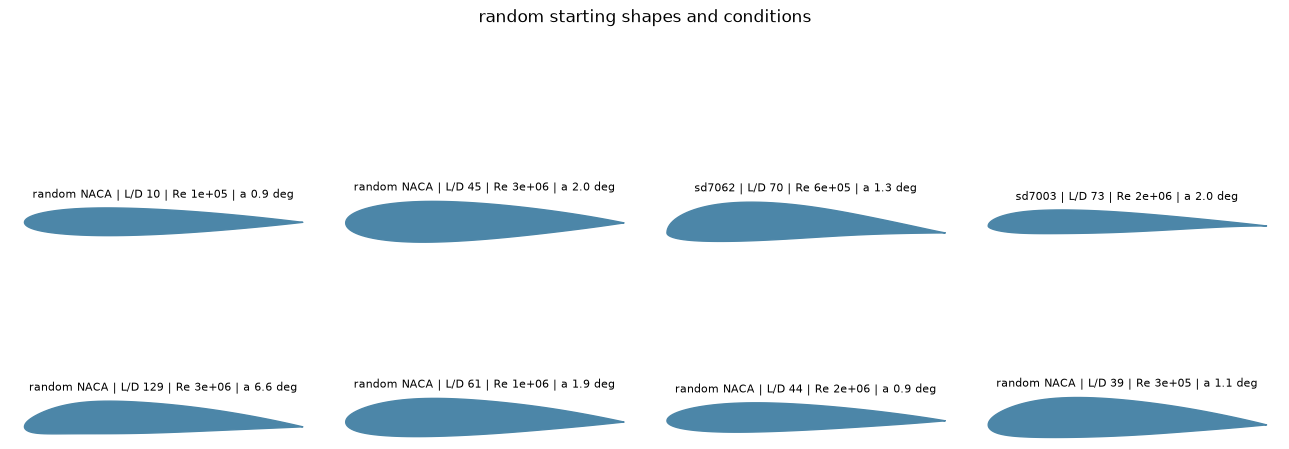

random walk L/D trace: [10.3 10.4  9.9  9.8 10.   9.8  9.7  9.9 10.1  9.7  9.7  9.2  9.2  9.1
  9.4  9.3  9.7  9.3  9.4  9.5  9.4  9.6  9.5 10.  10.1 10.  10.  10.1
 10.   9.8 10.2 10.2  9.9 10.1 10.2 10.3 10.4 10.6 10.5 10.6 10.6]
rejected moves: 0/40, final change in L/D: +0.3


In [4]:
# what the random tasks look like
env = TimeLimit(FoilEnv(), max_episode_steps=40)
fig, axs = plt.subplots(2, 4, figsize=(13, 6))
for ax, seed in zip(axs.flat, range(8)):
    obs, info = env.reset(seed=seed)
    yu, yl, _ = geom(env.unwrapped.wu, env.unwrapped.wl)
    ax.fill_between(X, yl, yu, color="#4C86A8")
    ax.set_title(f"{info['start']} | L/D {info['LD0']:.0f} | Re {env.unwrapped.Re:.0e} | a {env.unwrapped.alpha:.1f} deg",
                 fontsize=8)
    ax.set_aspect("equal"); ax.axis("off")
plt.suptitle("random starting shapes and conditions", y=0.99)
plt.tight_layout(); plt.show()

# and what a random policy does (for comparison later)
rng = np.random.default_rng(0)
obs, info = env.reset(seed=0)
done, log, rej = False, [info["LD0"]], 0
while not done:
    obs, r, term, trunc, info = env.step(int(rng.integers(32)))
    log.append(info["LD"]); rej += info["rejected"]; done = term or trunc
print(f"random walk L/D trace: {np.round(log, 1)}")
print(f"rejected moves: {rej}/40, final change in L/D: {log[-1]-log[0]:+.1f}")

## 3. Training the PPO agent

We use PPO from Stable-Baselines3 with the default MLP policy. PPO works well here because the reward is dense (every move gives feedback) and we do not need a value network tricks or anything fancy. We set gamma = 1 because the episode reward adds up to exactly (final L/D) minus (starting L/D), which is the thing we actually care about. The eval callback scores the greedy policy on 10 fresh random tasks every 10k steps, so the learning curve shows generalization and not luck on a fixed test set.


In [ ]:
import torch
torch.set_num_threads(1)  

model = PPO(
    "MlpPolicy", env, seed=SEED, device="cpu",
    n_steps=1024, batch_size=256, n_epochs=10,
    learning_rate=3e-4, ent_coef=0.01, gamma=1.0, gae_lambda=0.95,
)
eval_cb = EvalCallback(TimeLimit(FoilEnv(), max_episode_steps=40),
                       eval_freq=10_000, n_eval_episodes=10, deterministic=True, warn=False,
                       log_path="eval_log")   # without log_path SB3 does not record the curve

t0 = time.time()
model.learn(total_timesteps=TIMESTEPS, callback=eval_cb)
model.save("ppo_foil")
print(f"trained {TIMESTEPS:,} steps in {(time.time()-t0)/60:.1f} min")

Eval num_timesteps=10000, episode_reward=6.19 +/- 9.84
Episode length: 40.00 +/- 0.00
New best mean reward!


Eval num_timesteps=20000, episode_reward=8.35 +/- 8.55
Episode length: 40.00 +/- 0.00
New best mean reward!


Eval num_timesteps=30000, episode_reward=8.40 +/- 6.32
Episode length: 40.00 +/- 0.00
New best mean reward!


Eval num_timesteps=40000, episode_reward=11.03 +/- 14.61
Episode length: 40.00 +/- 0.00
New best mean reward!


Eval num_timesteps=50000, episode_reward=12.98 +/- 8.54
Episode length: 40.00 +/- 0.00
New best mean reward!


...

Eval num_timesteps=320000, episode_reward=22.01 +/- 13.19
Episode length: 40.00 +/- 0.00
New best mean reward!


Eval num_timesteps=330000, episode_reward=10.95 +/- 9.84
Episode length: 40.00 +/- 0.00


Eval num_timesteps=340000, episode_reward=11.20 +/- 9.15
Episode length: 40.00 +/- 0.00


Eval num_timesteps=350000, episode_reward=11.44 +/- 7.06
Episode length: 40.00 +/- 0.00


trained 350,000 steps in 8.9 min


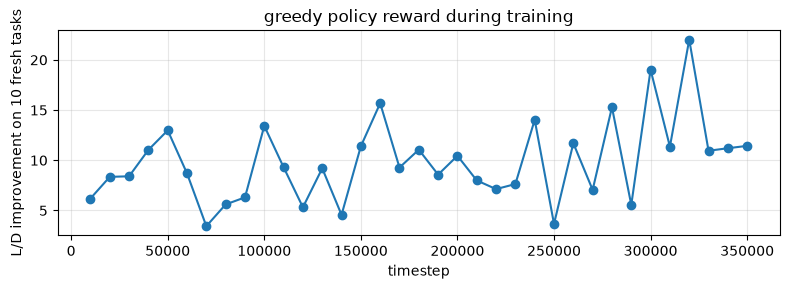

In [6]:
ts = eval_cb.evaluations_timesteps
rs = [np.mean(r) for r in eval_cb.evaluations_results]
plt.figure(figsize=(8, 3))
plt.plot(ts, rs, "o-")
plt.xlabel("timestep"); plt.ylabel("L/D improvement on 10 fresh tasks")
plt.title("greedy policy reward during training")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 4. Testing on shapes it has never seen

We run the trained policy on 8 brand new tasks. For comparison, a random policy gets the same 40 moves on the same tasks. We also re-check both shapes with the bigger "large" NeuralFoil model through a different code path (full coordinates instead of CST weights), to make sure the improvement is not just an artifact of the small fast model we trained on.

In [7]:
def run_policy(seed, policy):
    obs, info = env.reset(seed=seed)
    ld0, name0 = info["LD0"], info["start"]
    w0 = (env.unwrapped.wu.copy(), env.unwrapped.wl.copy())
    done, rej = False, 0
    while not done:
        obs, r, term, trunc, info = env.step(policy(obs))
        rej += info["rejected"]; done = term or trunc
    return ld0, name0, info, w0, (env.unwrapped.wu.copy(), env.unwrapped.wl.copy()), \
           env.unwrapped.alpha, env.unwrapped.Re, rej

env, rows = TimeLimit(FoilEnv(), max_episode_steps=40), []
for seed in range(2000, 2008):
    ld0, name0, fin, w0, w1, al, re_, rej = run_policy(seed, lambda o: int(model.predict(o, deterministic=True)[0]))
    _,   _,  fin_r, _,  _,  _,   _,  _    = run_policy(seed, lambda o: env.action_space.sample())
    a0 = nf.get_aero_from_coordinates(coords(*geom(*w0)[:2]), alpha=al, Re=re_, model_size="large")
    a1 = nf.get_aero_from_coordinates(coords(*geom(*w1)[:2]), alpha=al, Re=re_, model_size="large")
    rows.append(dict(seed=seed, start=name0, alpha=al, Re=re_, ld0=ld0, ld1=fin["LD"],
                     rand=fin_r["LD"], tmin=fin["tmin"], rej=rej,
                     ld0v=a0["CL"].item()/a0["CD"].item(), ld1v=a1["CL"].item()/a1["CD"].item(),
                     w0=w0, w1=w1))

print(f"{'seed':>4} {'start shape':<13} {'a':>4} {'Re':>8} | {'L/D in':>7} {'-> out':>7} {'(big model)':>15} | {'random':>7} | {'rej':>3}")
for r in rows:
    print(f"{r['seed']:>4} {r['start']:<13} {r['alpha']:>3.1f} {r['Re']:>8.0e} | {r['ld0']:>7.1f} {r['ld1']:>7.1f}"
          f" {r['ld0v']:>6.1f}->{r['ld1v']:<6.1f} | {r['rand']:>7.1f} | {r['rej']:>3}")

ppo_gain = np.mean([r["ld1"] - r["ld0"] for r in rows])
rnd_gain = np.mean([r["rand"] - r["ld0"] for r in rows])
n_better = sum(r["ld1"] > r["ld0"] for r in rows)
print(f"\nmean L/D change over 8 unseen tasks:  PPO {ppo_gain:+.1f}   random {rnd_gain:+.1f}")
print(f"PPO improved the L/D on {n_better}/8 tasks, and no move was ever rejected (shapes stayed valid)")

seed start shape      a       Re |  L/D in  -> out     (big model) |  random | rej
2000 random NACA   1.9    1e+06 |    30.4    36.1   33.1->36.9   |    30.1 |   0
2001 sd7003        3.9    5e+06 |   104.7   130.8  113.5->145.7  |    99.9 |   0
2002 random NACA   5.9    2e+05 |    65.8    73.9   66.8->67.7   |    64.4 |   0
2003 naca0012      6.4    4e+05 |    54.8    66.7   59.1->74.2   |    58.4 |   0
2004 random NACA   2.0    3e+06 |   110.1   137.0  128.9->145.2  |    99.6 |   0
2005 random NACA   4.0    6e+05 |    89.8   103.3  106.6->93.7   |    94.8 |   0
2006 random NACA   4.1    2e+06 |    80.7    98.8   90.2->109.1  |    80.3 |   0
2007 random NACA   5.6    6e+05 |    63.0    76.1   70.5->85.6   |    62.2 |   0

mean L/D change over 8 unseen tasks:  PPO +15.4   random -1.2
PPO improved the L/D on 8/8 tasks, and no move was ever rejected (shapes stayed valid)


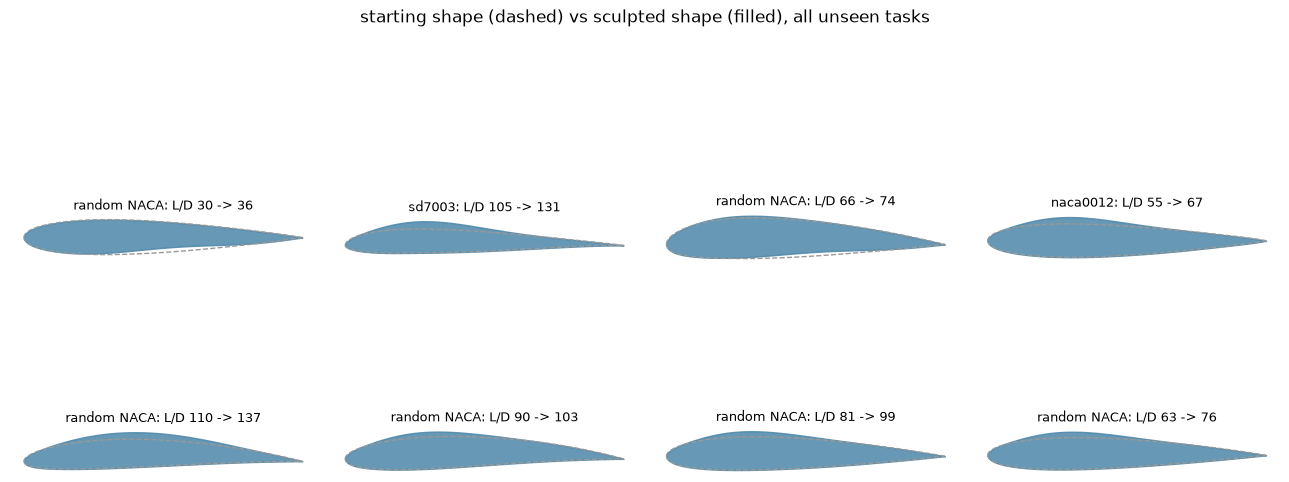

In [8]:
fig, axs = plt.subplots(2, 4, figsize=(13, 6.5))
for ax, r in zip(axs.flat, rows):
    yu0, yl0, _ = geom(*r["w0"])
    yu1, yl1, _ = geom(*r["w1"])
    ax.plot(X, yu0, X, yl0, color="0.6", lw=1, ls="--")         # starting shape
    ax.fill_between(X, yl1, yu1, color="#4C86A8", alpha=0.85)   # after 40 moves
    ax.set_title(f"{r['start']}: L/D {r['ld0']:.0f} -> {r['ld1']:.0f}", fontsize=9)
    ax.axis("off"); ax.set_aspect("equal")
plt.suptitle("starting shape (dashed) vs sculpted shape (filled), all unseen tasks", y=0.99)
plt.tight_layout(); plt.show()

## 5. Watching one episode step by step



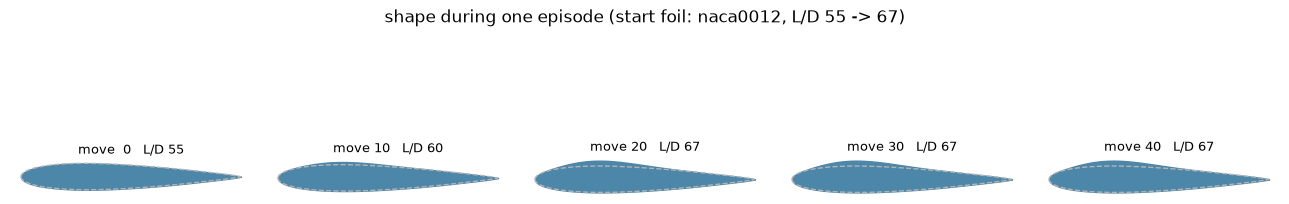

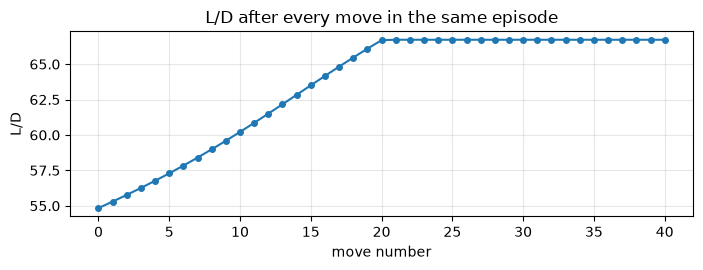

In [9]:
# roll out one greedy episode on an unseen task and record the shape after every move
obs, info = env.reset(seed=2003)
ld0, w_start, start_name = info["LD0"], (env.unwrapped.wu.copy(), env.unwrapped.wl.copy()), info["start"]
frames = [(env.unwrapped.wu.copy(), env.unwrapped.wl.copy(), env.unwrapped.ld)]
done = False
while not done:
    obs, r, term, trunc, info = env.step(int(model.predict(obs, deterministic=True)[0]))
    frames.append((env.unwrapped.wu.copy(), env.unwrapped.wl.copy(), env.unwrapped.ld))
    done = term or trunc

fig, axs = plt.subplots(1, 5, figsize=(13, 2.8))
for ax, i in zip(axs, [0, 10, 20, 30, 40]):
    wu, wl, ld = frames[i]
    yu, yl, _ = geom(wu, wl)
    yu0, yl0, _ = geom(*w_start)
    ax.plot(X, yu0, X, yl0, color="0.7", lw=1, ls="--")
    ax.fill_between(X, yl, yu, color="#4C86A8")
    ax.set_title(f"move {i:2d}   L/D {ld:.0f}", fontsize=9)
    ax.set_aspect("equal"); ax.axis("off")
plt.suptitle(f"shape during one episode (start foil: {start_name}, "
             f"L/D {ld0:.0f} -> {frames[-1][2]:.0f})", y=1.04)
plt.tight_layout(); plt.show()

plt.figure(figsize=(7, 2.8))
plt.plot([f[2] for f in frames], "o-", ms=4)
plt.xlabel("move number"); plt.ylabel("L/D")
plt.title("L/D after every move in the same episode")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()